# 6. Ensemble Boosting Regression (Gradient Boosting)

## Lý thuyết & Nguyên lý

### 6.1. Nguyên tắc Boosting — học tuần tự trên phần dư

Khác với Random Forest (các cây **độc lập song song**), Gradient Boosting xây dựng các cây **tuần tự**: cây thứ $m$ được huấn luyện để **sửa lỗi của cây tổng hợp $m-1 cây trước**. Với hàm mất mát bình phương (MSE), gradient âm của sai số chính là **phần dư (residual)**:

$$r_i^{(m)} = y_i - F_{m-1}(x_i) \qquad (\text{gradient của } \tfrac{1}{2}(y_i - F_{m-1}(x_i))^2 \text{ lấy dấu ngược})$$

Cập nhật mô hình theo **shrinkage** (hệ số học $\eta$ — learning rate):

$$F_m(x) = F_{m-1}(x) + \eta \cdot h_m(x), \qquad \eta \in (0, 1]$$

- $F_0(x) = \bar{y}$ (trung bình dữ liệu) — giá trị khởi tạo.
- $h_m(x)$ là hồi quy cây nhỏ (thường `max_depth` = 3–5) **học phần dư** $r^{(m)}$.
- $\eta$ nhỏ (0.01–0.1) buộc mô hình "bước chậm", cần nhiều cây hơn nhưng khái quát hóa tốt hơn — đánh đổi trực tiếp với `n_estimators`.

### 6.2. Gradient Descent khái quát

Với mất mát tổng quát $L(y, F(x))$, Boosting cập nhật theo **hướng ngược gradient**:

$$F_m(x) = F_{m-1}(x) - \eta \cdot \frac{\partial L(y, F)}{\partial F}\bigg|_{F = F_{m-1}}$$

MSE → gradient = phần dư (như trên). Log Loss (phân loại) → gradient = $\hat{p} - y$. Nhờ tính khái quát này, cùng một khung Gradient Boosting áp dụng được cho cả regression, classification, ranking, survival analysis...

### 6.3. Bagging vs Boosting — so sánh nhanh

| Tiêu chí | Bagging (Random Forest) | Boosting (GBR/XGBoost) |
| :--- | :--- | :--- |
| Huấn luyện các cây | **Song song, độc lập** | **Tuần tự, có thứ tự** |
| Mục tiêu mỗi cây | Giảm **variance** | Giảm **bias** (sửa lỗi cây trước) |
| Trọng số các cây | Ngang nhau ($1/B$) | Có trọng số theo learning rate $\eta$ |
| Overfitting | Khó overfit (thêm cây ổn định) | Dễ overfit nếu chạy quá nhiều vòng |
| Tốc độ huấn luyện | Song song, nhanh | Tuần tự, chậm hơn |


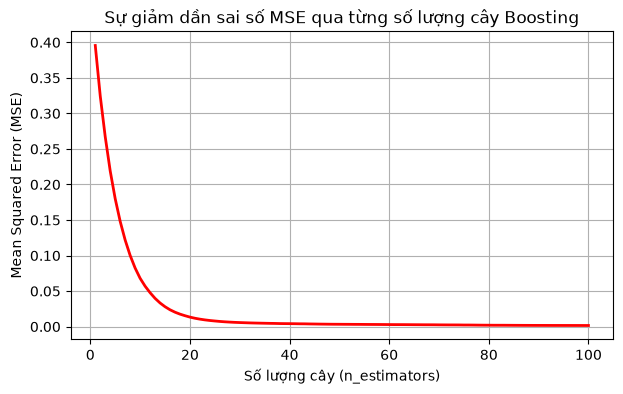

MSE sau 1 cây  : 0.3956
MSE sau 20 cây : 0.0134
MSE sau 100 cây: 0.0016


In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error

# 1. Dữ liệu: hàm sin + nhiễu
np.random.seed(42)
X = np.sort(5 * np.random.rand(100, 1), axis=0)
y = np.sin(X).ravel() + np.random.normal(0, 0.1, 100)

# 2. Huấn luyện Gradient Boosting và theo dõi MSE theo từng cây (staged)
gbr = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42).fit(X, y)
errors = [
    mean_squared_error(y, y_pred)
    for y_pred in gbr.staged_predict(X)
]

# 3. Vẽ đồ thị sự giảm dần sai số
plt.figure(figsize=(7, 4))
plt.plot(range(1, 101), errors, color='red', linewidth=2)
plt.title('Sự giảm dần sai số MSE qua từng số lượng cây Boosting')
plt.xlabel('Số lượng cây (n_estimators)')
plt.ylabel('Mean Squared Error (MSE)')
plt.grid(True)
plt.show()

print(f"MSE sau 1 cây  : {errors[0]:.4f}")
print(f"MSE sau 20 cây : {errors[19]:.4f}")
print(f"MSE sau 100 cây: {errors[-1]:.4f}")


## Ý nghĩa của biểu đồ

- Đường đỏ giảm **nhanh ở đầu** (mười cây đầu sửa phần lớn sai số) rồi **phẳng dần** về sau — mỗi cây mới chỉ đóng góp phần sửa nhỏ (đặc biệt khi $\eta$ nhỏ).
- Đây là lý do Boosting cần cơ chế **dừng sớm (early stopping)**: thêm cây vô hạn sau điểm này không cải thiện mà **có thể làm test MSE tăng** (overfitting) — trong ví dụ này, đường trên là **train MSE** nên luôn giảm, nhưng trên tập test sẽ có hình "nghèo hoá U".

---

## Tổng quan mô hình

### Ưu điểm

- **Hiệu năng top đầu** trên bài toán dữ liệu bảng (tabular) — thường thắng hầu hết mô hình tuyến tính và các mô hình truyền thống khác.
- **Tự xử lý phi tuyến, tương tác giữa đặc trưng** mà không cần phi tuyến tính hóa thủ công.
- **Ít phải chuẩn hóa dữ liệu** — dựa trên cây, bất biến đơn tuyến tính.
- **Cung cấp `feature_importances_`** và staged prediction để theo dõi hội tụ.
- Gradient Descent khái quát: thay hàm mất mát chỉ cần đổi gradient.

### Nhược điểm

- **Dễ overfitting** nếu `n_estimators` quá lớn hoặc `learning_rate` không phù hợp → cần early stopping / validation.
- **Tuning phức tạp**: `n_estimators`, `learning_rate`, `max_depth`, `subsample`, `min_samples_leaf` — nhiều tham số tương tác.
- **Dễ bị ảnh hưởng điểm ngoại lai** (vì squared error).
- **Không song song** — chậm hơn Random Forest khi số cây rất lớn.
- Huấn luyện tuần tự nên không tận dụng triệt để đa luồng như Bagging.

### Siêu tham số quan trọng

| Tham số | Vai trò | Gợi ý |
| :--- | :--- | :--- |
| `n_estimators` | Số cây boosting | Càng nhiều cây → càng dễ overfit; dùng với `staged_predict` để quan sát |
| `learning_rate` ($\eta$) | Kích thước bước sửa lỗi | 0.01–0.1; **giảm $\eta$ ⇒ tăng số cây**, đánh đổi kinh điển |
| `max_depth` | Độ sâu mỗi cây (mức độ weak learner) | 3–5 (cây nhỏ, không học quá chi tiết phần dư) |
| `subsample` | Tỷ lệ mẫu mỗi cây (= Stochastic Gradient Boosting) | 0.5–1.0; < 1 giúp giảm variance |
| `min_samples_leaf` | Số mẫu tối thiểu trong lá | Tăng lên để cây mượt, chống overfit |

### Các trường hợp sử dụng thực tế

| Lĩnh vực | Ứng dụng cụ thể | Đặc trưng đầu vào ($X$) | Mục tiêu ($y$) |
| :--- | :--- | :--- | :--- |
| **Khoa dữ liệu Kaggle** | Dự báo giá/chấm điểm (tabular) | Hỗn hợp số + phân loại đã mã hóa | Giá nhà, số lượt click |
| **Tài chính** | Dự báo dòng tiền, chấm điểm rủi ro | Lịch sử giao dịch, macro, hành vi | Doanh thu / xác suất nợ xấu (quy đổi) |
| **Bán lẻ** | Dự báo nhu cầu sản phẩm | Mùa vụ, khuyến mãi, giá, thời tiết | Số lượng bán ra |
| **Logistics** | Ước thời gian giao hàng | Quãng đường, mật độ giao thông, thời tiết | Thời gian (phút) |
| **Năng lượng** | Dự báo sản lượng điện mặt trời | Bóng mây, góc chiếu, nhiệt độ | Sản lượng kWh |

### Mẹo thực hành

- Bắt đầu với `learning_rate=0.1`, `max_depth=3`, rồi tăng `n_estimators` đến khi validation MSE plateau.
- `subsample < 1.0` (Stochastic GB) vừa tăng tốc vừa giảm overfitting.
- Trên dữ liệu bảng nhỏ/tb: Gradient Boosting (hoặc LightGBM/XGBoost) gần như luôn là mô hình mạnh nhất cần thử sau các baseline tuyến tính.


GBR lr=0.01 : Test MSE tốt nhất = 0.0398 (tại cây 299)
GBR lr=0.05 : Test MSE tốt nhất = 0.0393 (tại cây 67)
GBR lr=0.1  : Test MSE tốt nhất = 0.0394 (tại cây 32)
GBR lr=0.3  : Test MSE tốt nhất = 0.0400 (tại cây 13)
Random Forest      : Test MSE = 0.0539


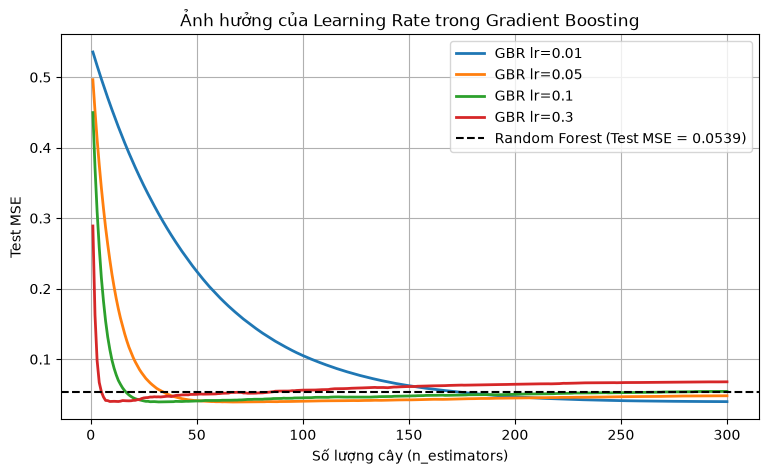

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

# 1. Dữ liệu lớn hơn, chia train/test để quan sát trên dữ liệu chưa thấy
np.random.seed(42)
X = np.sort(6 * np.random.rand(400, 1), axis=0)
y = np.sin(X).ravel() + np.random.normal(0, 0.2, X.shape[0])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 2. So sánh 4 learning rate khác nhau, theo dõi Test MSE qua 300 cây
learning_rates = [0.01, 0.05, 0.1, 0.3]
plt.figure(figsize=(9, 5))

for lr in learning_rates:
    gbr = GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=lr,
        max_depth=3,
        random_state=42,
    ).fit(X_train, y_train)
    test_errors = [mean_squared_error(y_test, p) for p in gbr.staged_predict(X_test)]
    plt.plot(range(1, 301), test_errors, linewidth=2, label=f'GBR lr={lr}')
    print(f"GBR lr={lr:<5}: Test MSE tốt nhất = {min(test_errors):.4f} (tại cây {int(np.argmin(test_errors)) + 1})")

# 3. Đường chuẩn tham chiếu: Random Forest
rf = RandomForestRegressor(n_estimators=300, random_state=42).fit(X_train, y_train)
rf_mse = mean_squared_error(y_test, rf.predict(X_test))
plt.axhline(rf_mse, color='black', linestyle='--', linewidth=1.5,
            label=f'Random Forest (Test MSE = {rf_mse:.4f})')
print(f"Random Forest      : Test MSE = {rf_mse:.4f}")

plt.xlabel('Số lượng cây (n_estimators)')
plt.ylabel('Test MSE')
plt.title('Ảnh hưởng của Learning Rate trong Gradient Boosting')
plt.legend()
plt.grid(True)
plt.show()


## Giải thích kết quả

- **lr = 0.3**: giảm MSE nhanh nhất ở giai đoạn đầu, nhưng đường **bắt đầu đi lên** sau vài chục cây → overfitting sớm. Learning rate lớn = bước sửa lỗi lớn, nhanh tụ hội nhưng dễ vượt qua điểm tối ưu.
- **lr = 0.1**: cân bằng — hội tụ vừa nhanh, plateau ổn định.
- **lr = 0.05 và 0.01**: chậm hơn nhiều, cần hàng trăm cây mới đạt MSE tốt, nhưng **khó overfit** và plateau thấp. Đây là lý do thực tế hay dùng `lr` rất nhỏ (0.01) + hàng nghìn cây + early stopping.
- Đường **đứt đen (Random Forest)** cho thấy: với dữ liệu nhỏ, 1D, sạch — Gradient Boosting thường có thể vượt Random Forest nhờ giảm bias chủ động.

**Quy tắc vàng:** $\eta$ và `n_estimators` đi đôi với nhau — giảm learning rate bao nhiêu thì phải tăng số cây bấy nhiêu.
